In [7]:
!nvidia-smi
!df -h /

Thu Sep 17 04:29:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
!pip install -q torchaudio pesq pystoi matplotlib
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
Device Name: Tesla T4


In [ ]:
import os

!mkdir -p data/LibriSpeech
!mkdir -p data/DEMAND

# 1. Download & Extract LibriSpeech dev-clean (337 MB)
if not os.path.exists("data/LibriSpeech/dev-clean"):
    print("Downloading LibriSpeech dev-clean...")
    !wget -c -q --show-progress https://www.openslr.org/resources/12/dev-clean.tar.gz
    !tar -xzf dev-clean.tar.gz -C data/LibriSpeech/

# 2. Download ESC-50 Environmental Noise (correct repo: karolpiczak)
!rm -f ESC-50.zip
if not os.path.exists("data/NOISE/ESC-50-master"):
    print("Downloading ESC-50 noise dataset...")
    !mkdir -p data/NOISE
    !wget -c -q --show-progress -O ESC-50.zip "https://github.com/karolpiczak/ESC-50/archive/master.zip"
    !unzip -q -o ESC-50.zip -d data/NOISE/

# 3. Download DEMAND noise (individual 16kHz zips from Zenodo record 1227121)
DEMAND_ENVS = ["DKITCHEN", "DLIVING", "DWASHING", "NFIELD", "NPARK", "NRIVER",
               "OHALLWAY", "OMEETING", "OOFFICE", "PCAFETER", "PRESTO",
               "PSTATION", "SPSQUARE", "STRAFFIC", "TBUS", "TCAR", "TMETRO"]

if not os.path.exists("data/DEMAND/DKITCHEN_16k"):
    print("Downloading DEMAND noise environments (16kHz)...")
    for env in DEMAND_ENVS:
        fname = f"{env}_16k"
        url = f"https://zenodo.org/records/1227121/files/{fname}.zip?download=1"
        print(f"  Downloading {fname}...")
        !wget -c -q --show-progress -O "{fname}.zip" "{url}"
        !unzip -q -o "{fname}.zip" -d data/DEMAND/
        !rm -f "{fname}.zip"

print("\n✅ VERIFICATION:")
!echo "LibriSpeech:" && ls data/LibriSpeech/dev-clean/ | head -5
!echo "ESC-50:" && ls data/NOISE/ESC-50-master/audio/ | head -5
!echo "DEMAND:" && ls data/DEMAND/ | head -10

DKITCHEN_16k.zip      1%[                    ]   1.81M   544KB/s    eta 3m 36s ^C
[DKITCHEN_16k.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of DKITCHEN_16k.zip or
        DKITCHEN_16k.zip.zip, and cannot find DKITCHEN_16k.zip.ZIP, period.
^C
[DLIVING_16k.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of DLIVING_16k.zip or
        DLIVING_16k.zip.zip, and cannot find DLIVING_16k.zip.ZIP, period.
DWASHING_16k.zip      5%[>                   ]   5.06M   582KB/s    eta 2m 51s ^C
[

In [14]:
import os
import glob

def get_dataset_info(name, path, extensions=["*.wav", "*.flac"]):
    print(f"\n{'='*60}")
    print(f"📂 {name}")
    print(f"   Path: {path}")
    print(f"{'='*60}")

    if not os.path.exists(path):
        print("   ❌ NOT FOUND")
        return

    total_files = 0
    total_size = 0
    ext_counts = {}

    for ext in extensions:
        files = glob.glob(os.path.join(path, "**", ext), recursive=True)
        ext_name = ext.replace("*", "")
        ext_counts[ext_name] = len(files)
        for f in files:
            total_size += os.path.getsize(f)
        total_files += len(files)

    # Count subdirectories
    subdirs = [d for d in glob.glob(os.path.join(path, "*")) if os.path.isdir(d)]

    print(f"   Total Audio Files : {total_files}")
    for ext_name, count in ext_counts.items():
        if count > 0:
            print(f"   ├── {ext_name} files    : {count}")
    print(f"   Total Size        : {total_size / (1024**3):.2f} GB ({total_size / (1024**2):.0f} MB)")
    print(f"   Subdirectories    : {len(subdirs)}")
    if subdirs:
        print(f"   Subdir Names      : {[os.path.basename(d) for d in sorted(subdirs)]}")

# 1. LibriSpeech
get_dataset_info(
    "LibriSpeech dev-clean (Clean Speech)",
    "data/LibriSpeech/dev-clean"
)

# 2. DEMAND Noise
get_dataset_info(
    "DEMAND Noise (Environmental Noise)",
    "data/DEMAND"
)

# 3. ESC-50 Noise (if downloaded)
get_dataset_info(
    "ESC-50 Environmental Sound Classification (Noise)",
    "data/NOISE/ESC-50-master/audio"
)

# Grand Total
print(f"\n{'='*60}")
print(f"📊 GRAND TOTAL SUMMARY")
print(f"{'='*60}")
all_paths = ["data/LibriSpeech/dev-clean", "data/DEMAND", "data/NOISE/ESC-50-master/audio"]
grand_files = 0
grand_size = 0
for p in all_paths:
    if os.path.exists(p):
        for ext in ["**/*.wav", "**/*.flac"]:
            files = glob.glob(os.path.join(p, ext), recursive=True)
            grand_files += len(files)
            for f in files:
                grand_size += os.path.getsize(f)

print(f"   Total Audio Files : {grand_files}")
print(f"   Total Dataset Size: {grand_size / (1024**3):.2f} GB ({grand_size / (1024**2):.0f} MB)")
print(f"   Free Disk Left    :")
!df -h / | tail -1 | awk '{print "   " $4 " available out of " $2}'



📂 LibriSpeech dev-clean (Clean Speech)
   Path: data/LibriSpeech/dev-clean
   Total Audio Files : 2703
   ├── .flac files    : 2703
   Total Size        : 0.33 GB (342 MB)
   Subdirectories    : 40
   Subdir Names      : ['1272', '1462', '1673', '174', '1919', '1988', '1993', '2035', '2078', '2086', '2277', '2412', '2428', '251', '2803', '2902', '3000', '3081', '3170', '3536', '3576', '3752', '3853', '422', '5338', '5536', '5694', '5895', '6241', '6295', '6313', '6319', '6345', '652', '777', '7850', '7976', '8297', '84', '8842']

📂 DEMAND Noise (Environmental Noise)
   Path: data/DEMAND
   Total Audio Files : 272
   ├── .wav files    : 272
   Total Size        : 2.43 GB (2490 MB)
   Subdirectories    : 17
   Subdir Names      : ['DKITCHEN', 'DLIVING', 'DWASHING', 'NFIELD', 'NPARK', 'NRIVER', 'OHALLWAY', 'OMEETING', 'OOFFICE', 'PCAFETER', 'PRESTO', 'PSTATION', 'SPSQUARE', 'STRAFFIC', 'TBUS', 'TCAR', 'TMETRO']

📂 ESC-50 Environmental Sound Classification (Noise)
   Path: data/NOISE/ESC-

In [1]:
!echo "=== LibriSpeech ===" && ls data/LibriSpeech/dev-clean/ | head -5
!echo "=== DEMAND ===" && ls data/DEMAND/
!echo "=== ESC-50 ===" && ls data/NOISE/ESC-50-master/audio/ | head -5

=== LibriSpeech ===
1272
1462
1673
174
1919
=== DEMAND ===
DKITCHEN  NFIELD  OHALLWAY  PCAFETER  SPSQUARE	TCAR
DLIVING   NPARK   OMEETING  PRESTO    STRAFFIC	TMETRO
DWASHING  NRIVER  OOFFICE   PSTATION  TBUS
=== ESC-50 ===
1-100032-A-0.wav
1-100038-A-14.wav
1-100210-A-36.wav
1-100210-B-36.wav
1-101296-A-19.wav


In [2]:
%%writefile config.py
import torch
import os

class Config:
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    NUM_WORKERS = 2
    SAMPLE_RATE = 16000
    DURATION_SEC = 3.0
    NUM_SAMPLES = int(SAMPLE_RATE * DURATION_SEC)
    N_FFT = 512
    HOP_LENGTH = 128
    WIN_LENGTH = 512
    MIN_SNR_DB = 0.0
    MAX_SNR_DB = 20.0
    IN_CHANNELS = 1
    OUT_CHANNELS = 1
    BASE_FILTERS = 32
    BATCH_SIZE = 16
    LEARNING_RATE = 1e-3
    NUM_EPOCHS = 15
    WEIGHT_DECAY = 1e-5
    CLEAN_SPEECH_DIR = "./data/LibriSpeech/dev-clean"
    NOISE_DIR = "./data/DEMAND"
    CHECKPOINT_DIR = "./checkpoints"
    SAVED_AUDIO_DIR = "./output_audio"

os.makedirs(Config.CHECKPOINT_DIR, exist_ok=True)
os.makedirs(Config.SAVED_AUDIO_DIR, exist_ok=True)

Writing config.py


In [4]:
%%writefile dataset.py
import os
import glob
import random
import torch
import torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset
from config import Config

class SyntheticSpeechDataset(Dataset):
    def __init__(self, clean_dir, noise_dir, is_train=True):
        super().__init__()
        self.is_train = is_train
        self.clean_files = sorted(
            glob.glob(os.path.join(clean_dir, "**/*.flac"), recursive=True) +
            glob.glob(os.path.join(clean_dir, "**/*.wav"), recursive=True)
        )
        self.noise_files = sorted(
            glob.glob(os.path.join(noise_dir, "**/*.wav"), recursive=True) +
            glob.glob(os.path.join(noise_dir, "**/*.flac"), recursive=True)
        )
        print(f"  Found {len(self.clean_files)} clean speech files")
        print(f"  Found {len(self.noise_files)} noise files")

    def __len__(self):
        return len(self.clean_files)

    def _load_and_resample(self, file_path):
        waveform, sr = torchaudio.load(file_path)
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
        if sr != Config.SAMPLE_RATE:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=Config.SAMPLE_RATE)
            waveform = resampler(waveform)
        return waveform.squeeze(0)

    def _fix_length(self, audio, target_length):
        audio_len = audio.shape[0]
        if audio_len < target_length:
            audio = F.pad(audio, (0, target_length - audio_len))
        elif audio_len > target_length:
            start = random.randint(0, audio_len - target_length) if self.is_train else (audio_len - target_length) // 2
            audio = audio[start : start + target_length]
        return audio

    def _mix_at_snr(self, clean, noise, snr_db):
        clean_power = torch.mean(clean ** 2)
        noise_power = torch.mean(noise ** 2)
        if clean_power < 1e-8: clean_power = torch.tensor(1e-8)
        if noise_power < 1e-8: noise_power = torch.tensor(1e-8)
        target_noise_power = clean_power / (10.0 ** (snr_db / 10.0))
        scale_factor = torch.sqrt(target_noise_power / noise_power)
        scaled_noise = noise * scale_factor
        return clean + scaled_noise, scaled_noise

    def __getitem__(self, idx):
        clean_waveform = self._fix_length(self._load_and_resample(self.clean_files[idx]), Config.NUM_SAMPLES)

        if len(self.noise_files) > 0:
            noise_idx = random.randint(0, len(self.noise_files) - 1)
            noise_waveform = self._fix_length(self._load_and_resample(self.noise_files[noise_idx]), Config.NUM_SAMPLES)
        else:
            noise_waveform = torch.randn_like(clean_waveform) * 0.01

        snr_db = random.uniform(Config.MIN_SNR_DB, Config.MAX_SNR_DB) if self.is_train else 10.0
        noisy_waveform, scaled_noise = self._mix_at_snr(clean_waveform, noise_waveform, snr_db)

        window = torch.hann_window(Config.WIN_LENGTH)
        stft_clean = torch.stft(clean_waveform, n_fft=Config.N_FFT, hop_length=Config.HOP_LENGTH, win_length=Config.WIN_LENGTH, window=window, return_complex=True)
        stft_noisy = torch.stft(noisy_waveform, n_fft=Config.N_FFT, hop_length=Config.HOP_LENGTH, win_length=Config.WIN_LENGTH, window=window, return_complex=True)
        stft_noise = torch.stft(scaled_noise, n_fft=Config.N_FFT, hop_length=Config.HOP_LENGTH, win_length=Config.WIN_LENGTH, window=window, return_complex=True)

        clean_mag = torch.abs(stft_clean)
        noisy_mag = torch.abs(stft_noisy)
        noise_mag = torch.abs(stft_noise)
        noisy_phase = torch.angle(stft_noisy)

        target_mask = torch.clamp(clean_mag / (clean_mag + noise_mag + 1e-8), 0.0, 1.0)

        return {
            "noisy_mag": noisy_mag.unsqueeze(0),
            "clean_mag": clean_mag.unsqueeze(0),
            "target_mask": target_mask.unsqueeze(0),
            "noisy_phase": noisy_phase,
            "noisy_waveform": noisy_waveform,
            "clean_waveform": clean_waveform
        }

Overwriting dataset.py


In [5]:
%%writefile model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from config import Config

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=(2, 2)):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True)
        )
    def forward(self, x): return self.conv(x)

class DeconvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=(2, 2)):
        super().__init__()
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, output_padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.deconv(x)

class SpectrogramUNet(nn.Module):
    def __init__(self, in_channels=Config.IN_CHANNELS, out_channels=Config.OUT_CHANNELS, base_filters=Config.BASE_FILTERS):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, base_filters)
        self.enc2 = ConvBlock(base_filters, base_filters * 2)
        self.enc3 = ConvBlock(base_filters * 2, base_filters * 4)
        self.enc4 = ConvBlock(base_filters * 4, base_filters * 8)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_filters * 8, base_filters * 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_filters * 8),
            nn.ReLU(inplace=True)
        )

        self.dec4 = DeconvBlock(base_filters * 8, base_filters * 4)
        self.dec3 = DeconvBlock(base_filters * 8, base_filters * 2)
        self.dec2 = DeconvBlock(base_filters * 4, base_filters)
        self.dec1 = DeconvBlock(base_filters * 2, base_filters)

        self.final_mask = nn.Sequential(
            nn.Conv2d(base_filters, out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def _match_size(self, source, target):
        diff_h = target.size(2) - source.size(2)
        diff_w = target.size(3) - source.size(3)
        return F.pad(source, [diff_w // 2, diff_w - diff_w // 2, diff_h // 2, diff_h - diff_h // 2])

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        b = self.bottleneck(e4)

        d4 = self._match_size(self.dec4(b), e3)
        d3 = self._match_size(self.dec3(torch.cat([d4, e3], dim=1)), e2)
        d2 = self._match_size(self.dec2(torch.cat([d3, e2], dim=1)), e1)
        d1 = self._match_size(self.dec1(torch.cat([d2, e1], dim=1)), x)

        predicted_mask = self.final_mask(d1)
        estimated_clean_mag = predicted_mask * x
        return predicted_mask, estimated_clean_mag

Writing model.py


In [6]:
%%writefile utils.py
import torch
import torch.nn as nn
from config import Config

def reconstruct_audio(estimated_mag, noisy_phase):
    if estimated_mag.dim() == 4:
        estimated_mag = estimated_mag.squeeze(1)
    real = estimated_mag * torch.cos(noisy_phase)
    imag = estimated_mag * torch.sin(noisy_phase)
    complex_stft = torch.complex(real, imag)
    window = torch.hann_window(Config.WIN_LENGTH).to(estimated_mag.device)
    return torch.istft(complex_stft, n_fft=Config.N_FFT, hop_length=Config.HOP_LENGTH,
                       win_length=Config.WIN_LENGTH, window=window, length=Config.NUM_SAMPLES)

def compute_sisdr(reference, estimate, eps=1e-8):
    if reference.dim() == 1:
        reference = reference.unsqueeze(0)
        estimate = estimate.unsqueeze(0)
    reference = reference - torch.mean(reference, dim=-1, keepdim=True)
    estimate = estimate - torch.mean(estimate, dim=-1, keepdim=True)
    dot = torch.sum(estimate * reference, dim=-1, keepdim=True)
    ref_energy = torch.sum(reference ** 2, dim=-1, keepdim=True) + eps
    target = (dot / ref_energy) * reference
    noise = estimate - target
    return torch.mean(10.0 * torch.log10((torch.sum(target**2, dim=-1, keepdim=True) + eps) /
                                          (torch.sum(noise**2, dim=-1, keepdim=True) + eps)))

class HybridSpectralLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.L1Loss()
        self.mse = nn.MSELoss()
    def forward(self, pred_mask, target_mask, est_mag, target_mag):
        return self.mse(pred_mask, target_mask) + 2.0 * self.l1(est_mag, target_mag)

Writing utils.py


In [7]:
%%writefile train.py
import os
import time
import torch
from torch.utils.data import DataLoader, random_split
from config import Config
from dataset import SyntheticSpeechDataset
from model import SpectrogramUNet
from utils import HybridSpectralLoss, reconstruct_audio, compute_sisdr

def train_model():
    print(f"Device: {Config.DEVICE}")
    print("="*60)

    full_dataset = SyntheticSpeechDataset(Config.CLEAN_SPEECH_DIR, Config.NOISE_DIR, is_train=True)
    total = len(full_dataset)
    val_size = max(1, int(0.1 * total))
    train_size = total - val_size
    train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

    print(f"  Train samples: {train_size}, Val samples: {val_size}")
    print("="*60)

    train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True, num_workers=Config.NUM_WORKERS, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=Config.NUM_WORKERS)

    model = SpectrogramUNet().to(Config.DEVICE)
    criterion = HybridSpectralLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)

    total_params = sum(p.numel() for p in model.parameters())
    print(f"  Model Parameters: {total_params:,}")
    print("="*60)

    best_val_loss = float("inf")

    for epoch in range(1, Config.NUM_EPOCHS + 1):
        t0 = time.time()

        model.train()
        train_loss = 0.0
        for batch in train_loader:
            noisy_mag = batch["noisy_mag"].to(Config.DEVICE)
            clean_mag = batch["clean_mag"].to(Config.DEVICE)
            target_mask = batch["target_mask"].to(Config.DEVICE)

            optimizer.zero_grad()
            pred_mask, est_mag = model(noisy_mag)
            loss = criterion(pred_mask, target_mask, est_mag, clean_mag)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0.0
        val_sisdr = 0.0
        with torch.no_grad():
            for batch in val_loader:
                noisy_mag = batch["noisy_mag"].to(Config.DEVICE)
                clean_mag = batch["clean_mag"].to(Config.DEVICE)
                target_mask = batch["target_mask"].to(Config.DEVICE)
                noisy_phase = batch["noisy_phase"].to(Config.DEVICE)
                clean_wav = batch["clean_waveform"].to(Config.DEVICE)

                pred_mask, est_mag = model(noisy_mag)
                loss = criterion(pred_mask, target_mask, est_mag, clean_mag)
                val_loss += loss.item()

                est_wav = reconstruct_audio(est_mag, noisy_phase)
                val_sisdr += compute_sisdr(clean_wav, est_wav).item()

        val_loss /= len(val_loader)
        val_sisdr /= len(val_loader)
        elapsed = time.time() - t0

        print(f"Epoch [{epoch:02d}/{Config.NUM_EPOCHS}] ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val SI-SDR: {val_sisdr:+.2f} dB")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            path = os.path.join(Config.CHECKPOINT_DIR, "best_speech_enhancer.pth")
            torch.save({"epoch": epoch, "model_state_dict": model.state_dict(),
                        "val_loss": val_loss, "val_sisdr": val_sisdr}, path)
            print(f"   --> Best model saved! (Val Loss: {val_loss:.4f})")

    print("="*60)
    print("Training Complete!")

if __name__ == "__main__":
    train_model()

Writing train.py


In [8]:
!python train.py

Device: cuda
  Found 2703 clean speech files
  Found 272 noise files
  Train samples: 2433, Val samples: 270
  Model Parameters: 1,477,857
Epoch [01/15] (133.1s) | Train Loss: 0.1591 | Val Loss: 0.1522 | Val SI-SDR: +18.71 dB
   --> Best model saved! (Val Loss: 0.1522)
Epoch [02/15] (129.6s) | Train Loss: 0.1270 | Val Loss: 0.1248 | Val SI-SDR: +19.05 dB
   --> Best model saved! (Val Loss: 0.1248)
Epoch [03/15] (127.5s) | Train Loss: 0.1203 | Val Loss: 0.1631 | Val SI-SDR: +18.31 dB
Epoch [04/15] (126.2s) | Train Loss: 0.1186 | Val Loss: 0.1362 | Val SI-SDR: +19.63 dB
Epoch [05/15] (128.4s) | Train Loss: 0.1140 | Val Loss: 0.1197 | Val SI-SDR: +18.59 dB
   --> Best model saved! (Val Loss: 0.1197)
Epoch [06/15] (126.0s) | Train Loss: 0.1118 | Val Loss: 0.1104 | Val SI-SDR: +19.44 dB
   --> Best model saved! (Val Loss: 0.1104)
Epoch [07/15] (126.5s) | Train Loss: 0.1112 | Val Loss: 0.1062 | Val SI-SDR: +20.04 dB
   --> Best model saved! (Val Loss: 0.1062)
Epoch [08/15] (126.6s) | Train L

Loaded best model from epoch 15 | Val SI-SDR: +19.64 dB
  Found 2703 clean speech files
  Found 272 noise files

SI-SDR: +18.25 dB

🔊 1. Original Clean Speech:



🔊 2. Noisy Mixture (Speech + Noise):



🔊 3. Model Enhanced Output (Denoised):


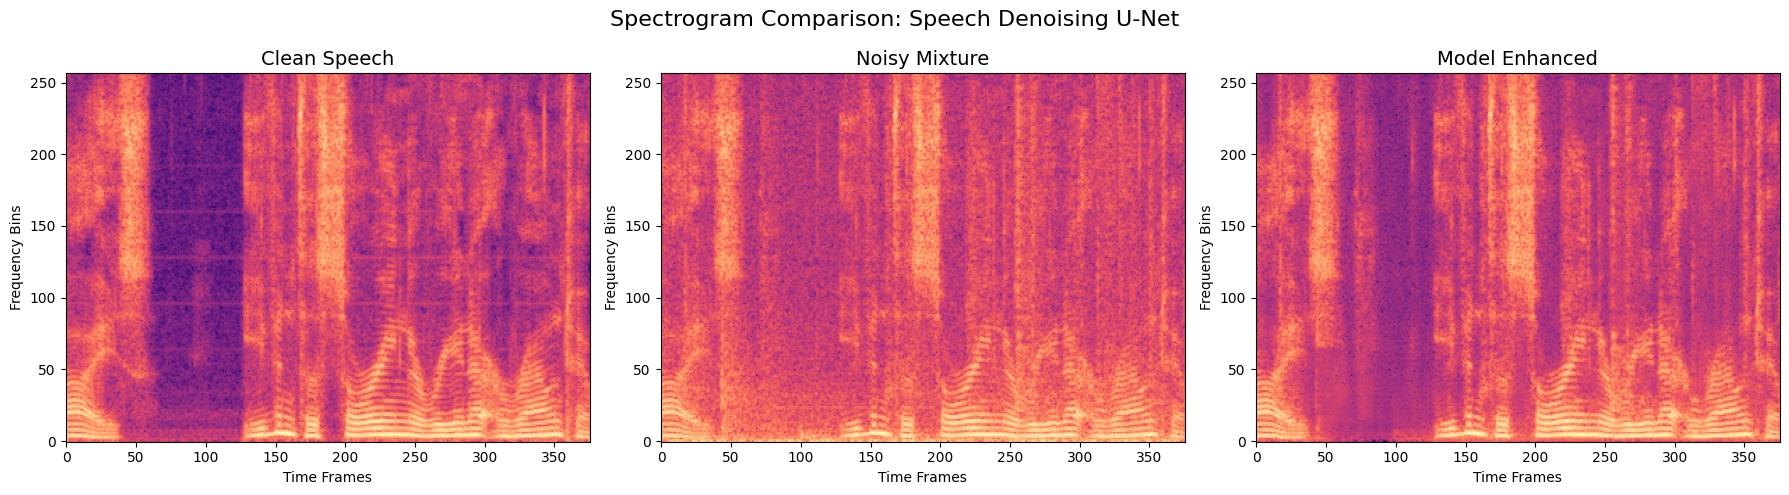

In [9]:
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from config import Config
from dataset import SyntheticSpeechDataset
from model import SpectrogramUNet
from utils import reconstruct_audio, compute_sisdr

model = SpectrogramUNet().to(Config.DEVICE)
ckpt = torch.load("./checkpoints/best_speech_enhancer.pth", map_location=Config.DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
print(f"Loaded best model from epoch {ckpt['epoch']} | Val SI-SDR: {ckpt['val_sisdr']:+.2f} dB")

ds = SyntheticSpeechDataset(Config.CLEAN_SPEECH_DIR, Config.NOISE_DIR, is_train=False)
sample = ds[42]

noisy_mag = sample["noisy_mag"].unsqueeze(0).to(Config.DEVICE)
noisy_phase = sample["noisy_phase"].unsqueeze(0).to(Config.DEVICE)
clean_wav = sample["clean_waveform"]
noisy_wav = sample["noisy_waveform"]

with torch.no_grad():
    _, est_mag = model(noisy_mag)
    est_wav = reconstruct_audio(est_mag, noisy_phase).squeeze().cpu()

sisdr = compute_sisdr(clean_wav.unsqueeze(0), est_wav.unsqueeze(0)).item()
print(f"\nSI-SDR: {sisdr:+.2f} dB")

print("\n🔊 1. Original Clean Speech:")
display(Audio(clean_wav.numpy(), rate=Config.SAMPLE_RATE))

print("\n🔊 2. Noisy Mixture (Speech + Noise):")
display(Audio(noisy_wav.numpy(), rate=Config.SAMPLE_RATE))

print("\n🔊 3. Model Enhanced Output (Denoised):")
display(Audio(est_wav.numpy(), rate=Config.SAMPLE_RATE))

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
titles = ["Clean Speech", "Noisy Mixture", "Model Enhanced"]
mags = [sample["clean_mag"].squeeze(), sample["noisy_mag"].squeeze(), est_mag.squeeze().cpu()]
for i, (title, mag) in enumerate(zip(titles, mags)):
    axs[i].imshow(torch.log(mag + 1e-6), aspect='auto', origin='lower', cmap='magma')
    axs[i].set_title(title, fontsize=14)
    axs[i].set_xlabel("Time Frames")
    axs[i].set_ylabel("Frequency Bins")
plt.suptitle("Spectrogram Comparison: Speech Denoising U-Net", fontsize=16)
plt.tight_layout()
plt.savefig("spectrogram_comparison.png", dpi=150)
plt.show()

In [ ]:
# Option A: Download directly to your laptop
from google.colab import files
files.download('./checkpoints/best_speech_enhancer.pth')

# Option B: Save to Google Drive (persistent storage)
from google.colab import drive
drive.mount('/content/drive')

import shutil
shutil.copy('./checkpoints/best_speech_enhancer.pth',
            '/content/drive/MyDrive/best_speech_enhancer_unet_phase1.pth')
print("✅ Model saved to Google Drive!")

In [ ]:
#To resume training later from this checkpoint:

model = SpectrogramUNet().to(Config.DEVICE)
ckpt = torch.load("best_speech_enhancer.pth", map_location=Config.DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
# Continue training from here...